In [1]:
from pathlib import Path

PROJECT = Path.cwd().parent
CLIPS = PROJECT / "data" / "clips"
print(PROJECT)
from pathlib import Path
PROJECT = Path.cwd().parent

c:\Users\seree\OneDrive\Desktop\FalseNine


In [2]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2

PROJECT = Path.cwd().parent
CLIPS = PROJECT / "data" / "clips"
OUT = PROJECT / "outputs" / "05_pitch_mapping"
OUT.mkdir(parents=True, exist_ok=True)

print("Clips with labels:")
label_files = sorted(CLIPS.rglob("Labels-GameState.json"))
for i, p in enumerate(label_files): print(" ", i, p.relative_to(CLIPS))
print("\nVideos made in notebook 02/04:")
for i, v in enumerate(sorted((PROJECT / "data" / "videos").glob("*.mp4"))): print(" ", i, v.name)

Clips with labels:
  0 SNGS-021\Labels-GameState.json
  1 SNGS-022\Labels-GameState.json
  2 SNGS-023\Labels-GameState.json

Videos made in notebook 02/04:
  0 SNGS-021.mp4
  1 SNGS-022.mp4
  2 SNGS-023.mp4


In [3]:
LABELS = label_files[0]          # <- the one that matches your notebook 04 video
data = json.loads(LABELS.read_text())
print(list(data.keys())); print(data["info"])

imgs = pd.DataFrame(data["images"])
print(imgs.head(3).to_string()); print(len(imgs), "images")

ann = data["annotations"]
print(pd.Series([a.get("supercategory") for a in ann]).value_counts())

obj = next(a for a in ann if a.get("supercategory") == "object")
print(json.dumps(obj, indent=1)[:900])

pit = next((a for a in ann if a.get("supercategory") == "pitch"), None)
if pit:
    print("\npitch line names and number of points:")
    print({k: len(v) for k, v in pit["lines"].items()})
    k0 = next(iter(pit["lines"])); print(k0, pit["lines"][k0][:2])

['info', 'images', 'annotations', 'categories']
{'version': '1.3', 'game_id': '2', 'id': '021', 'num_tracklets': '25', 'action_position': '82617', 'action_class': 'Kick-off', 'visibility': 'visible', 'game_time_start': '1 - 01:16', 'game_time_stop': '1 - 01:46', 'clip_start': '76000', 'clip_stop': '106000', 'name': 'SNGS-021', 'im_dir': 'img1', 'frame_rate': 25, 'seq_length': 750, 'im_ext': '.jpg'}
   is_labeled    image_id   file_name  height  width  has_labeled_person  has_labeled_pitch  has_labeled_camera ignore_regions_y ignore_regions_x
0        True  2021000001  000001.jpg    1080   1920                True               True                True               []               []
1        True  2021000002  000002.jpg    1080   1920                True               True                True               []               []
2        True  2021000003  000003.jpg    1080   1920                True               True                True               []               []
750 images
obj

In [4]:
idcol = "image_id" if "image_id" in imgs.columns else "id"
img_frame = {r[idcol]: int(Path(r["file_name"]).stem) for _, r in imgs.iterrows()}

rows = []
for a in ann:
    if a.get("supercategory") != "object": continue
    bi, bp = a.get("bbox_image"), a.get("bbox_pitch")
    if not bi or not bp: continue
    at = a.get("attributes", {})
    rows.append(dict(frame=img_frame[a["image_id"]], track_id=a.get("track_id"),
                     role=at.get("role"), team=at.get("team"), jersey=at.get("jersey"),
                     x=bi["x"], y=bi["y"], w=bi["w"], h=bi["h"],
                     px=bp["x_bottom_middle"], py=bp["y_bottom_middle"]))
gt = pd.DataFrame(rows)
print(gt.describe().round(1).to_string())
print(gt.role.value_counts().to_dict(), gt.team.value_counts().to_dict())
print("frames:", gt.frame.min(), "to", gt.frame.max())

         frame  track_id        x        y        w        h       px       py
count  12678.0   12678.0  12678.0  12678.0  12678.0  12678.0  12678.0  12678.0
mean     373.6      11.6    895.4    397.3     48.9    103.8    -14.1      9.3
std      217.2       6.8    479.8    182.3     21.2     38.9     15.9     18.6
min        1.0       1.0      0.0      0.0      3.0      8.0    -48.5    -37.3
25%      177.0       6.0    534.0    256.0     33.0     80.0    -26.3     -0.4
50%      379.0      11.0    897.0    393.0     47.0    104.0    -15.2     12.4
75%      558.0      16.0   1260.0    502.0     61.0    127.0     -0.3     24.3
max      750.0      25.0   1913.0   1052.0    140.0    223.0     24.0     40.0
{'player': 10338, 'referee': 1191, 'ball': 752, 'goalkeeper': 397} {'left': 5857, 'right': 4878}
frames: 1 to 750


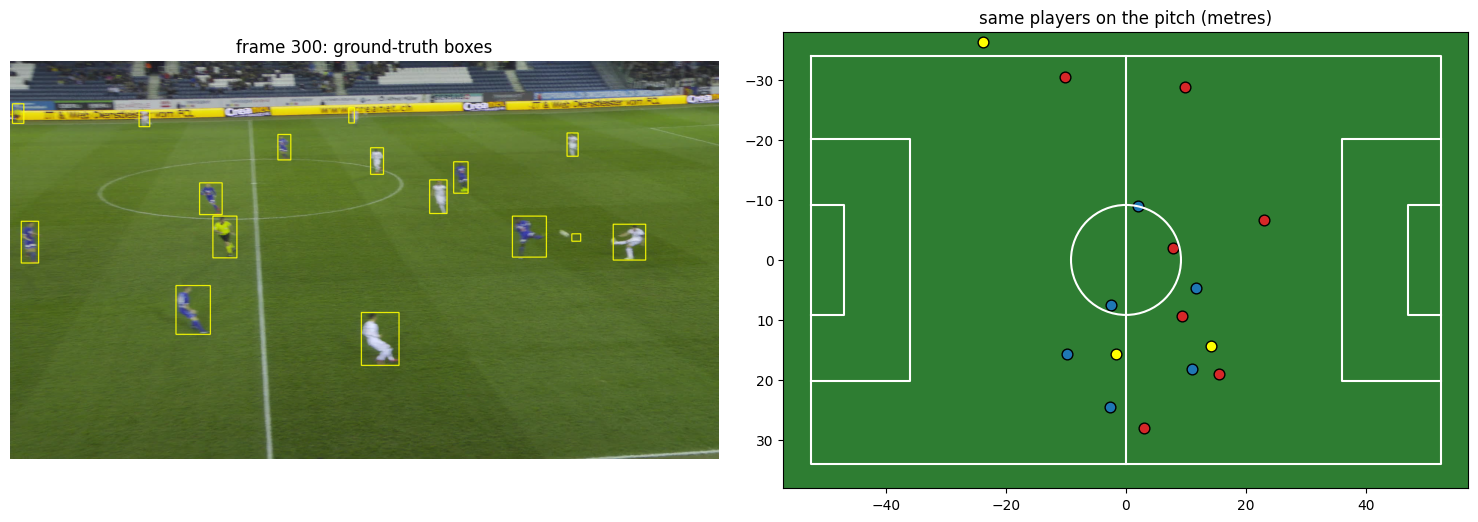

In [5]:
def draw_pitch(ax):
    L, Wd = 52.5, 34
    ax.plot([-L, L, L, -L, -L], [-Wd, -Wd, Wd, Wd, -Wd], "w-", lw=1.5)
    ax.plot([0, 0], [-Wd, Wd], "w-", lw=1.5)
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=False, ec="w", lw=1.5))
    for s in (-1, 1):
        ax.plot([s * L, s * (L - 16.5), s * (L - 16.5), s * L], [-20.16, -20.16, 20.16, 20.16], "w-", lw=1.5)
        ax.plot([s * L, s * (L - 5.5), s * (L - 5.5), s * L], [-9.16, -9.16, 9.16, 9.16], "w-", lw=1.5)
    ax.set_facecolor("#2e7d32"); ax.set_xlim(-57, 57); ax.set_ylim(-38, 38)
    ax.set_aspect("equal"); ax.invert_yaxis()      # y points toward the camera, like the broadcast view

FRAME_N = 300                                      # same moment as START in notebook 04
first = imgs.file_name.iloc[0]
img_path = next(LABELS.parent.rglob(Path(first).name)).parent / f"{FRAME_N:06d}{Path(first).suffix}"
frame = cv2.imread(str(img_path)); H, W = frame.shape[:2]
f = gt[gt.frame == FRAME_N].copy()
if f.x.max() <= 1.5: f[["x", "w"]] *= W; f[["y", "h"]] *= H   # in case boxes are fractions

TEAM_C = {"left": "tab:blue", "right": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for _, r in f.iterrows():
    c = TEAM_C.get(r.team, "yellow")
    cv2.rectangle(frame, (int(r.x), int(r.y)), (int(r.x + r.w), int(r.y + r.h)), (0, 255, 255), 2)
    ax[1].scatter(r.px, r.py, c=c, s=60, edgecolors="k")
ax[0].imshow(frame[..., ::-1]); ax[0].axis("off"); ax[0].set_title(f"frame {FRAME_N}: ground-truth boxes")
draw_pitch(ax[1]); ax[1].set_title("same players on the pitch (metres)")
plt.tight_layout(); plt.savefig(OUT / "gt_frame_vs_pitch.png", dpi=130); plt.show()

In [6]:
people = gt[gt.role.isin(["player", "goalkeeper", "referee"])].copy()
people["fx"] = people.x + people.w / 2          # bottom-middle of the box = feet
people["fy"] = people.y + people.h

Hs, rows = {}, []
for fr, g in people.groupby("frame"):
    if len(g) < 6: continue
    src = g[["fx", "fy"]].values.astype(np.float32)
    dst = g[["px", "py"]].values.astype(np.float32)
    H, inl = cv2.findHomography(src, dst, cv2.RANSAC, 1.5)     # 1.5 m tolerance
    if H is None: continue
    proj = cv2.perspectiveTransform(src.reshape(-1, 1, 2), H).reshape(-1, 2)
    err = np.linalg.norm(proj - dst, axis=1)
    Hs[fr] = H
    rows.append(dict(frame=fr, n=len(g), inliers=int(inl.sum()),
                     median_err=np.median(err), p90_err=np.percentile(err, 90)))
res = pd.DataFrame(rows)
print(len(Hs), "of", gt.frame.nunique(), "frames have a homography")
print(res[["n", "inliers", "median_err", "p90_err"]].describe().round(2).to_string())

750 of 750 frames have a homography
            n  inliers  median_err  p90_err
count  750.00   750.00      750.00   750.00
mean    15.90    15.81        0.10     0.24
std      1.57     1.58        0.05     0.14
min     11.00    11.00        0.03     0.07
25%     15.00    15.00        0.07     0.16
50%     16.00    16.00        0.09     0.20
75%     17.00    17.00        0.12     0.26
max     19.00    19.00        0.38     1.76


In [7]:
import sys
sys.path.append(str(PROJECT / "src"))
from football_eval import iou

START = 300                                   # same START as notebook 04
tr = pd.read_csv(PROJECT / "outputs" / "04_tracking" / "tracks_teams.csv")
gt_by_frame = {n: g.reset_index(drop=True) for n, g in people.groupby("frame")}

rows = []
for r in tr.itertuples():
    n = START + int(r.frame) + 1              # video frame 0 = image file 000001
    if n not in Hs: continue
    X, Y = cv2.perspectiveTransform(
        np.array([[[(r.x1 + r.x2) / 2, r.y2]]], dtype=np.float32), Hs[n])[0, 0]
    g = gt_by_frame[n]
    ious = [iou([r.x1, r.y1, r.x2, r.y2], [a.x, a.y, a.x + a.w, a.y + a.h]) for a in g.itertuples()]
    j = int(np.argmax(ious))
    rows.append(dict(frame=int(r.frame), track_id=r.track_id, team=r.team, X=X, Y=Y,
                     matched=ious[j] >= 0.5,
                     err=float(np.hypot(X - g.px[j], Y - g.py[j])) if ious[j] >= 0.5 else np.nan))
proj = pd.DataFrame(rows)
proj.to_csv(OUT / "tracks_on_pitch.csv", index=False)

m = proj[proj.matched]
print("our boxes:", len(proj), "| matched to a real player (IoU>=0.5):", len(m), f"({100*len(m)/len(proj):.0f}%)")
print("position error in metres: median", m.err.median().round(2),
      "| mean", m.err.mean().round(2), "| 90th percentile", m.err.quantile(.9).round(2))

our boxes: 1813 | matched to a real player (IoU>=0.5): 1616 (89%)
position error in metres: median 0.31 | mean 0.43 | 90th percentile 0.85


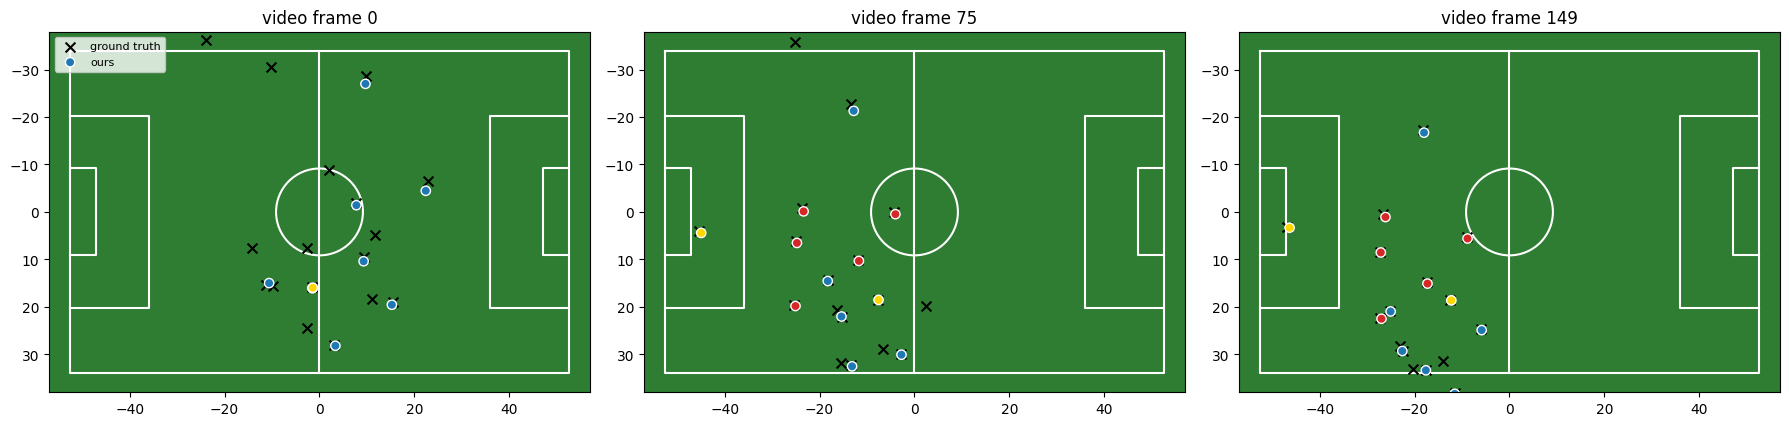

In [8]:
TEAM_C = {0: "tab:blue", 1: "tab:red", -1: "gold", -2: "gray"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, k in zip(axes, [0, 75, 149]):
    n = START + k + 1
    draw_pitch(ax)
    g = gt_by_frame[n]
    ax.scatter(g.px, g.py, marker="x", c="k", s=50, label="ground truth", zorder=3)
    p = proj[proj.frame == k]
    ax.scatter(p.X, p.Y, c=[TEAM_C[int(t)] for t in p.team], s=45, edgecolors="w", label="ours", zorder=4)
    ax.set_title(f"video frame {k}")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "pitch_view_ours_vs_gt.png", dpi=130); plt.show()

## Findings (SNGS-021, 150 frames, calibration from ground truth)
- Pitch positions are in metres (105x68 m pitch, origin at the centre spot). A homography fitted on the
  annotated players' feet explains SoccerNet's own pitch positions to a median of 0.09 m in all 750
  frames, so a flat-ground mapping is accurate enough for this camera.
- Using that known calibration, our tracked boxes were projected to the pitch. 89% of our 1,813 boxes
  matched an annotated person (IoU >= 0.5); median position error 0.31 m, mean 0.43 m, 90th percentile
  0.85 m. This isolates the error from our detector's box placement.
- Not measured here: players we missed, and calibration error when the camera calibration is not given.
  Calibration comes from ground-truth data here, so this is not yet an end-to-end video-to-pitch result.
- The ball is not mapped: it is often in the air, so a ground-plane homography does not apply.